In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

In [2]:
df = pd.read_csv("../Datasets/AusGas.csv")
df.head()

,Month,GasProd
0,Jan-1956,1709
1,Feb-1956,1646
2,Mar-1956,1794
3,Apr-1956,1878
4,May-1956,2173


In [3]:
y = df['GasProd']
print(y)
print("len : ",len(y))

0       1709
1       1646
2       1794
3       1878
4       2173
       ...  
471    49013
472    56624
473    61739
474    66600
475    60054
Name: GasProd, Length: 476, dtype: int64
len :  476


In [4]:
y_train , y_test = df['GasProd'][:-12] , df['GasProd'][-12:]
y_train.shape, y_test.shape

((464,), (12,))

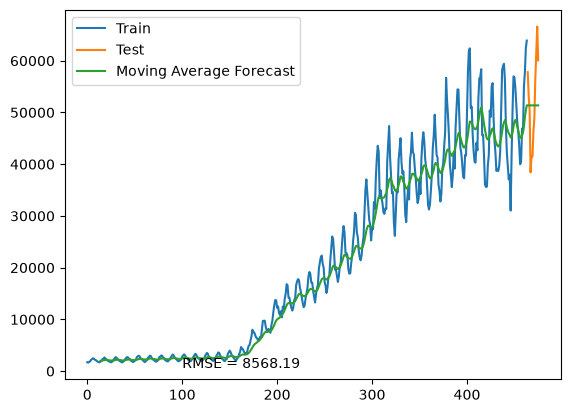

In [5]:
span = 15
fcast = y_train.rolling(window = span).mean()
MA = fcast.iloc[-1]
MA_Series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast , MA_Series] , ignore_index=True) # moving average forecast

plt.plot(y_train , label = 'Train')
plt.plot(y_test , label = 'Test')
plt.plot(MA_fcast , label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test , MA_Series) , 2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

In [7]:
from statsmodels.tsa.api import SimpleExpSmoothing

Text(100, 600, 'RMSE = 8920.31')

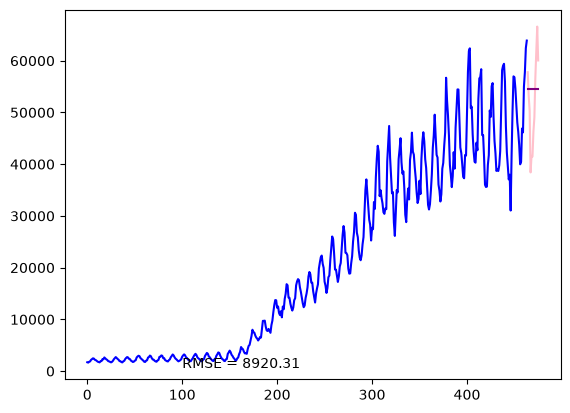

In [10]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train,initialization_method="estimated")

fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')


In [11]:
from statsmodels.tsa.api import Holt

Text(100, 600, 'RMSE = 9059.93')

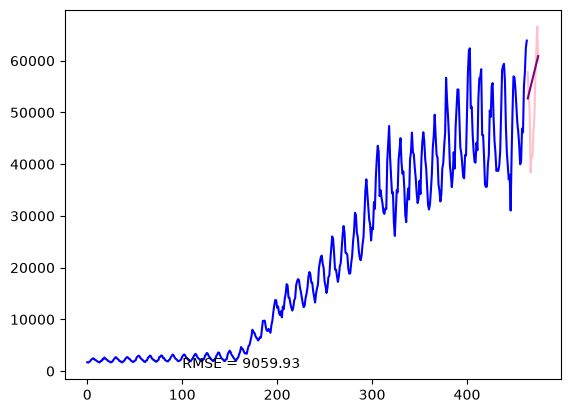

In [14]:
alpha ,beta = 0.1 , 0.2
holt = Holt(y_train, initialization_method="estimated")

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

Text(100, 600, 'RMSE = 9259.16')

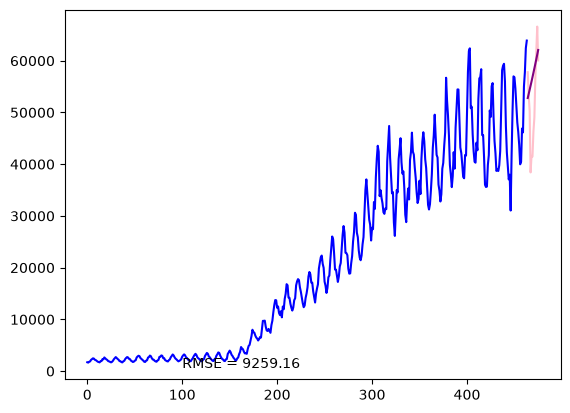

In [15]:
alpha ,beta = 0.1 , 0.2
holt = Holt(y_train , exponential=True, initialization_method="estimated")  # just changes equation but output looks same

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

Text(100, 600, 'RMSE = 8574.65')

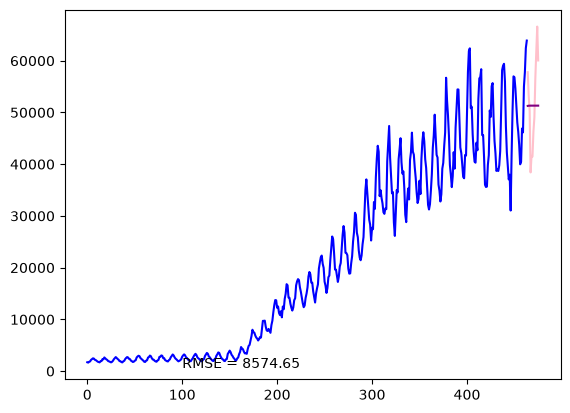

In [17]:
alpha ,beta, phi = 0.1 , 0.2, 0.3
holt = Holt(y_train , damped_trend=True, initialization_method="estimated")   

fit1 = holt.fit(smoothing_level=alpha , smoothing_trend = beta , damping_trend=phi , optimized=False)
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

Text(100, 600, 'RMSE = 8573.48')

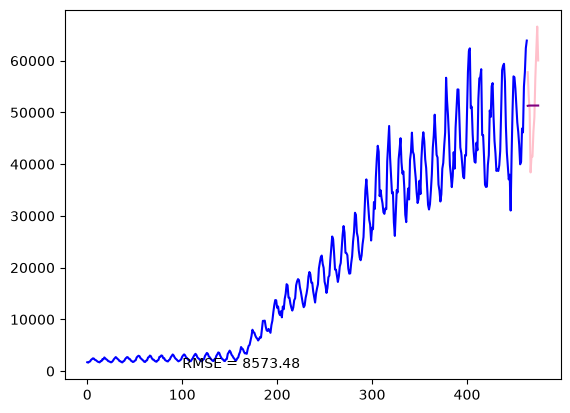

In [18]:
alpha ,beta, phi = 0.1 , 0.2, 0.3
holt = Holt(y_train , damped_trend=True , exponential=True, initialization_method="estimated")   

fit1 = holt.fit(smoothing_level= alpha , smoothing_trend = beta , damping_trend=phi , optimized=False)
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

# Exponential Smoothing

In [20]:
from statsmodels.tsa.api import ExponentialSmoothing

Text(100, 600, 'RMSE = 3944.71')

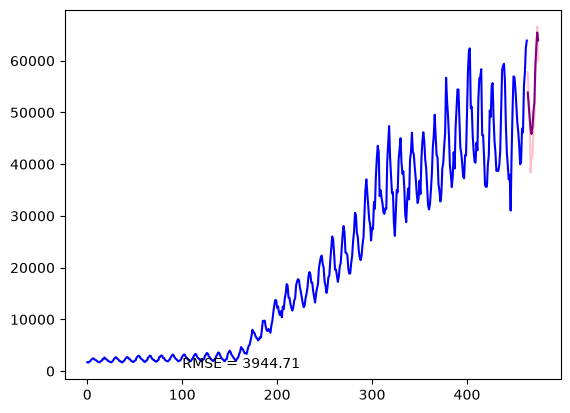

In [22]:
alpha ,beta, gamma = 0.1 , 0.2, 0.1
hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   

fit1 = hw_add.fit(smoothing_level= alpha , smoothing_trend = beta , smoothing_seasonal=gamma )
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

Text(100, 600, 'RMSE = 2404.57')

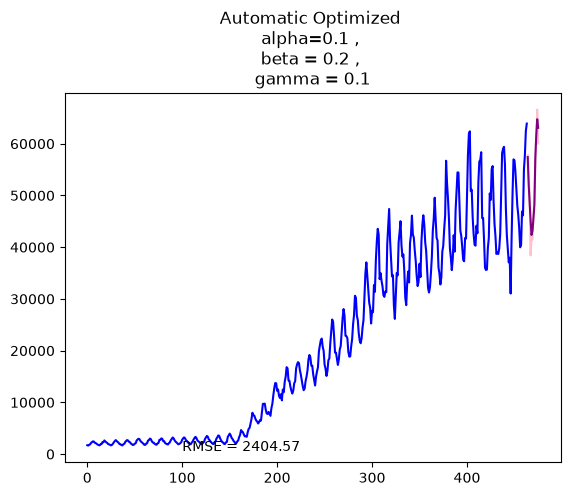

In [23]:
 
hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   

fit1 = hw_add.fit(optimized=True )  # calculated best garams does gridsearch of values
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

plt.title(f'Automatic Optimized \nalpha={alpha} , \nbeta = {beta} , \ngamma = {gamma}')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

In [24]:
alpha , beta , gamma = np.linspace(0.01,0.99,10) , np.linspace(0.01 , 0.99,10) , np.linspace(0.01 , 0.99,10)

scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
             
            hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   
            
            fit1 = hw_add.fit(smoothing_level=a , smoothing_trend=b, smoothing_seasonal=g)  
            fcast1 = fit1.forecast(len(y_test)) 
               

            scores.append([a,b,g, root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta', 'gamma','score'])
df_scores.sort_values('score')

  0%|          | 0/10 [00:00<?, ?it/s]C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
C:\ProgramData\anaconda3\Lib\s

,alpha,beta,gamma,score
425,0.445556,0.227778,0.554444,2.346541e+03
324,0.336667,0.227778,0.445556,2.411165e+03
405,0.445556,0.010000,0.554444,2.447454e+03
353,0.336667,0.554444,0.336667,2.448287e+03
354,0.336667,0.554444,0.445556,2.454129e+03
...,...,...,...,...
799,0.772222,0.990000,0.990000,3.828949e+07
979,0.990000,0.772222,0.990000,6.712625e+07
998,0.990000,0.990000,0.881111,2.350540e+09
989,0.990000,0.881111,0.990000,9.565620e+09


Text(100, 600, 'RMSE = 2346.29')

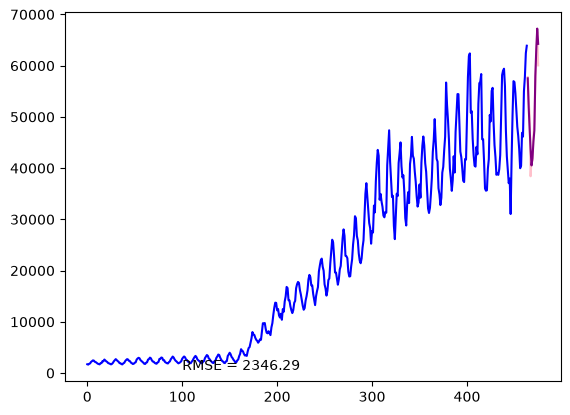

In [25]:
alpha ,beta, gamma = 0.445556 ,0.227778, 0.554444
hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='add')   

fit1 = hw_add.fit(smoothing_level= alpha , smoothing_trend = beta , smoothing_seasonal=gamma )
fcast1 = fit1.forecast(len(y_test)) 

y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
plt.text(100,600,f'RMSE = {rms}')

# ARIMA

In [26]:
model = ARIMA(y_train, order=(2,1,1))
model_fit = model.fit()
print("Coefficient %s" % model_fit.params)
pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, pred)
print("Test RMSE : %.2f" % error)

Coefficient ar.L1    -1.425393e-02
ar.L2     2.638232e-01
ma.L1     2.726234e-01
sigma2    6.250386e+06
dtype: float64
Test RMSE : 16411.42


C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


<Axes: >

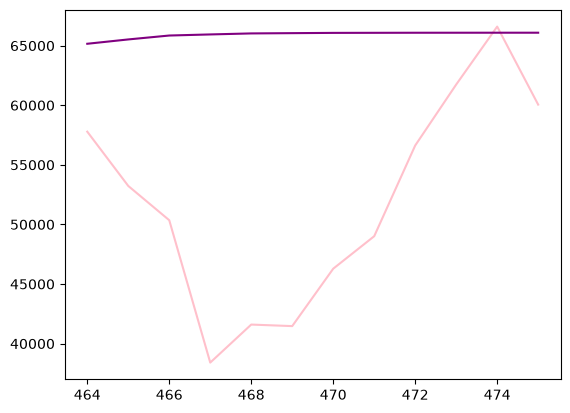

In [27]:
y_test.plot(color="pink")
pred.plot(color="purple")

In [28]:
from pmdarima.arima import auto_arima

In [29]:
model = auto_arima(y_train,trace=True,error_action='ignore',suppress_warnings=True)
model = ARIMA(y_train,order=(2,1,2))
model_fit = model.fit()
print('coefficient: %s' % model_fit.params)
predictions = model_fit.predict(start=len(y_train),end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test,predictions)
print('test RMSE: %.3f '%error)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=8355.115, Time=1.28 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=8632.352, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=8589.946, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=8603.593, Time=0.08 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=8631.502, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=8571.932, Time=0.52 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=8577.053, Time=0.17 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=8326.858, Time=1.34 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=8426.132, Time=1.02 sec
 ARIMA(4,1,2)(0,0,0)[0] intercept   : AIC=8270.030, Time=2.06 sec
 ARIMA(4,1,1)(0,0,0)[0] intercept   : AIC=8404.137, Time=1.43 sec
 ARIMA(5,1,2)(0,0,0)[0] intercept   : AIC=8391.024, Time=2.52 sec
 ARIMA(4,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.33 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.04 sec
 ARIMA(5,1,1)(0,0,0)[0] intercept   : AIC=8

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
plt.plot(y_test)
plt.plot(predictions)
plt.text(100,600,f'RMSE = {error}')

In [32]:
s_model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=3.47 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=8632.352, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=8255.565, Time=1.20 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=8438.509, Time=1.11 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=8631.502, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=8589.946, Time=0.05 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=2.56 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=8170.931, Time=2.28 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=8438.053, Time=0.71 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=8218.685, Time=4.78 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=8204.884, Time=6.39 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=8371.138, Time=2.18 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=6.18 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=8219.426, Time=1.45 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept

KeyboardInterrupt: 

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=3.36 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=8632.352, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=8255.565, Time=1.03 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=8438.509, Time=0.81 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=8631.502, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=8589.946, Time=0.04 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=2.67 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=8170.931, Time=2.52 sec
 ARIMA(1,1,0)(0,0,1)[12] intercept   : AIC=8438.053, Time=1.01 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=8218.685, Time=4.67 sec
 ARIMA(1,1,0)(1,0,2)[12] intercept   : AIC=8204.884, Time=6.43 sec
 ARIMA(1,1,0)(0,0,2)[12] intercept   : AIC=8371.138, Time=2.33 sec
 ARIMA(1,1,0)(2,0,2)[12] intercept   : AIC=inf, Time=6.48 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=8219.426, Time=1.47 sec
 ARIMA(2,1,0)(1,0,1)[12] intercept

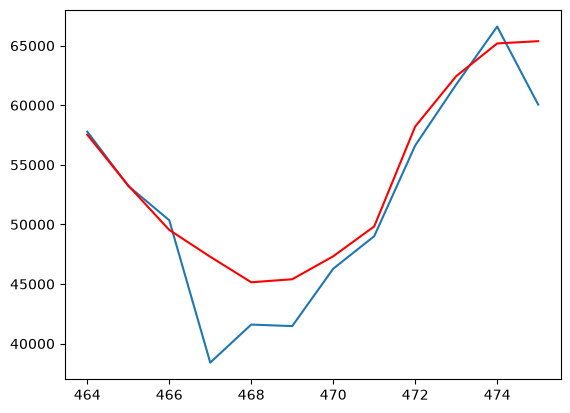

In [33]:
model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)

forecast = model.predict(n_periods=len(y_test))
forecast = pd.DataFrame(forecast, index = y_test.index, columns=['Prediction'])
rmse = root_mean_squared_error(y_test, forecast)
print('Test RMSE: %.3f' % rmse)

plt.plot(y_test)
plt.plot(forecast, color='red')
plt.show()

In [34]:
from pmdarima.pipeline import Pipeline
from pmdarima.preprocessing import BoxCoxEndogTransformer
import pmdarima as pm